# Volatility-Managed Equity + Defensive-Sector Pair Overlay — Backtest Notebook
**2270 Financial Modeling, Nova SBE — Group assignment**

**Moodle group:** _TODO: group name_
**Members:** _TODO: names + student numbers_
**GitHub repository:** https://github.com/Ben10Nova/FinancialModellingGroupN
**Streamlit app:** _TODO: deployed URL_

This notebook reproduces every number, table and figure in the prospectus.

### Setup
1. Open in Google Colab (colab.research.google.com) → *File → Upload notebook*.
2. *Runtime → Run all*. No data files are needed: all data is downloaded from the Yahoo Finance API via `yfinance`. Runtime ≈ 1–2 minutes.
3. Sample period and every assumption are set explicitly in the **Parameters** cell.
4. If Yahoo Finance rate-limits the download, the data check stops with an error: wait a minute and run again. Yahoo occasionally revises historical dividend adjustments, so a later re-run can differ from the prospectus in the last decimals.

### Strategy in one paragraph
**Sleeve 1 – volatility-managed S&P 500.** At each month-end we measure SPY's realised volatility over the last 21 trading days and hold `15% / realised vol` of capital in SPY (capped at 2×). The remainder sits in T-bills (or is borrowed at T-bill + 0.5% when exposure > 100%).
**Sleeve 2 – defensive-sector pair overlay.** At each year-end we estimate every S&P 500 sector ETF's beta to SPY over the past year and select the **two most defensive (lowest-beta) sectors** as next year's pair. Because both legs share the same defensive profile, short-term gaps between them tend to close. Each day we compute the z-score of the log price ratio versus its 60-day mean. Beyond ±2 we buy the cheap leg and short the rich leg (100% of capital each); we close when |z| < 0.5. Long/short, so approximately market neutral.

In [1]:
%pip install -q yfinance statsmodels
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, yfinance as yf
pd.set_option('display.width', 200)
print('yfinance', yf.__version__, '| pandas', pd.__version__)

Note: you may need to restart the kernel to use updated packages.


yfinance 1.8.0 | pandas 3.0.5


## 1. Parameters (all assumptions in one place)

In [2]:
START, END = '2006-01-01', '2025-12-31'   # evaluation window: first and last return day (inclusive)
DATA_START = '1999-01-01'                 # sector ETFs start Dec-1998; earlier years serve as warm-up / formation data
IS_END = '2015-12-31'                     # split for the in-sample / out-of-sample check

# Sleeve 1: volatility-managed SPY
TARGET_VOL = 0.15     # annualised volatility target
VOL_DAYS   = 21       # look-back for realised volatility (~1 month)
MAX_LEV    = 2.0      # cap on SPY exposure

# Sleeve 2: pair overlay
SECTORS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']   # the 9 original Select Sector SPDRs
BETA_YEARS = 1        # look-back (calendar years) for the beta estimate used to pick the pair
Z_WIN, Z_IN, Z_OUT = 60, 2.0, 0.5
PAIR_SIZE = 1.0       # notional per leg as a fraction of equity

# Implementation costs
COST       = 0.0010   # 10 bp of notional traded (spread + commission + slippage)
FIN_SPREAD = 0.0050   # borrowing cost above the T-bill rate, p.a.
SHORT_FEE  = 0.0025   # stock-borrow fee on short notional, p.a.

ASSETS  = ['SPY'] + SECTORS
TICKERS = ASSETS + ['^SP500TR', '^IRX']

## 2. Data
* **Source:** Yahoo Finance through the `yfinance` API.
* **Adjustment:** `auto_adjust=True` → prices are adjusted for splits **and dividends**, so returns are total returns.
* **Universe:** SPY plus the 9 original Select Sector SPDR ETFs, all trading continuously since December 1998. The universe is fixed in advance, so there is no survivorship selection.
* **Benchmark:** `^SP500TR`, the S&P 500 total-return index (dividends reinvested).
* **Risk-free rate:** `^IRX`, the 13-week US T-bill yield (% p.a.). Daily rf = yield / 100 / 252, using the yield known at the previous close.
* **Frequency:** daily data for signals and trading; monthly returns (compounded from daily) for the performance statistics.

In [3]:
raw = yf.download(TICKERS, start=DATA_START, end=pd.Timestamp(END) + pd.Timedelta(days=1),
                  auto_adjust=True, progress=False)['Close'][TICKERS]

# The four checks from Lecture 3: shape, date range, missing values, plot
print('shape:', raw.shape)
print('date range:', raw.index.min().date(), '->', raw.index.max().date())
print('missing values per column:\n', raw.isna().sum().to_string())

Crumb fetch rate-limited (HTTP 429), continuing without crumb


shape: (6791, 12)
date range: 1999-01-04 -> 2025-12-31
missing values per column:
 Ticker
SPY         0
XLB         0
XLE         0
XLF         0
XLI         0
XLK         0
XLP         0
XLU         0
XLV         0
XLY         0
^SP500TR    0
^IRX        8


dropna removed 0 of 6791 rows; sample now 1999-01-04 -> 2025-12-31


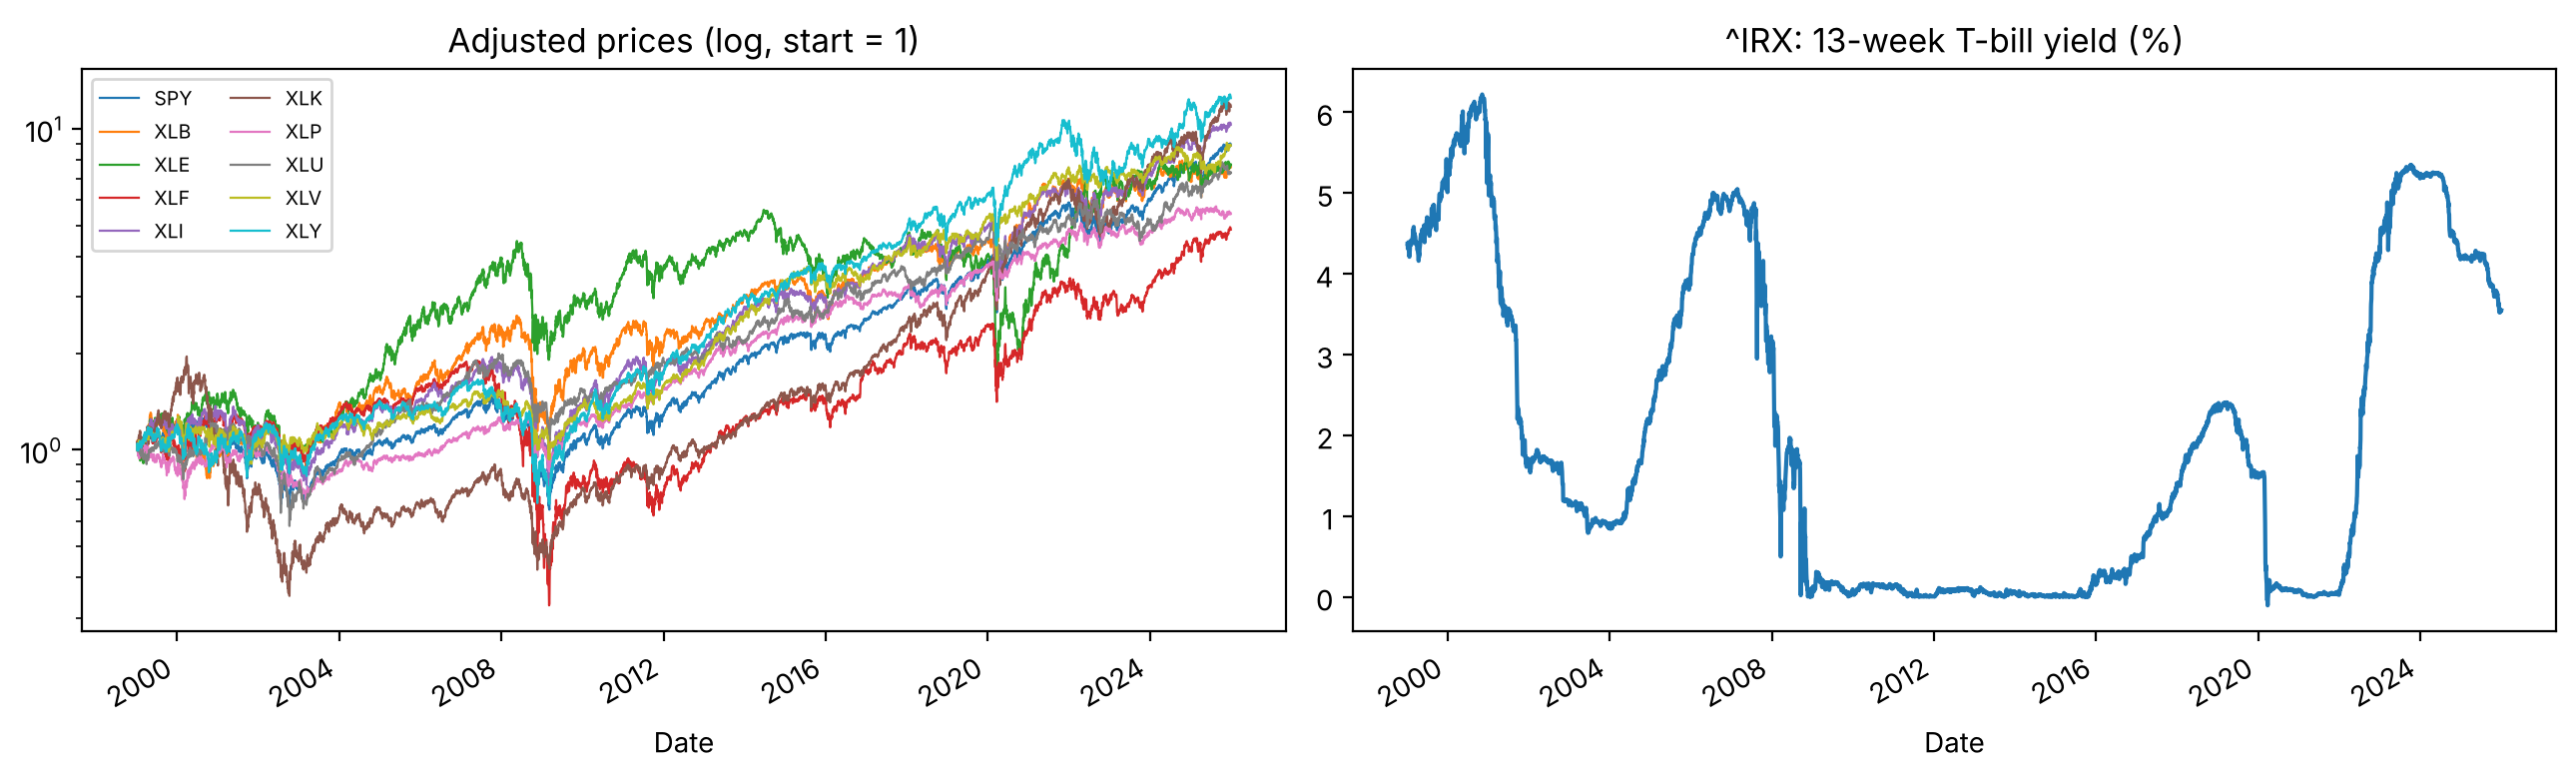

In [4]:
assert raw[ASSETS + ['^SP500TR']].notna().all().all(), 'download incomplete (rate limit?): re-run this cell'
px = raw.copy()
px['^IRX'] = px['^IRX'].ffill()           # T-bill quote occasionally missing on a trading day: carry last yield
n0 = len(px)
px = px.dropna()
print(f'dropna removed {n0 - len(px)} of {n0} rows; sample now {px.index.min().date()} -> {px.index.max().date()}')
assert px.index.min() < pd.Timestamp(START) and px.index.max() == pd.Timestamp(END), 'sample does not cover START..END'

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(px[ASSETS] / px[ASSETS].iloc[0]).plot(ax=ax[0], logy=True, lw=.8, title='Adjusted prices (log, start = 1)')
ax[0].legend(ncol=2, fontsize=7)
px['^IRX'].plot(ax=ax[1], title='^IRX: 13-week T-bill yield (%)')
plt.tight_layout(); plt.show()

In [5]:
ret = px[ASSETS + ['^SP500TR']].pct_change()
rf_d = (px['^IRX'] / 100 / 252).shift(1)     # yield known at t-1 is earned on day t

# Sanity check: SPY (adjusted) vs the S&P 500 total-return index should differ only by SPY's ~0.09% fee
yr = (1 + ret.loc[START:END, ['SPY', '^SP500TR']]).groupby(lambda d: d.year).prod() - 1
print('mean annual return SPY vs ^SP500TR:', yr.mean().round(4).to_dict(),
      '| correlation of daily returns:', round(ret.loc[START:END, 'SPY'].corr(ret.loc[START:END, '^SP500TR']), 4))

mean annual return SPY vs ^SP500TR: {'SPY': 0.1243, '^SP500TR': 0.1252} | correlation of daily returns: 0.9938


## 3. Signals
Every signal uses only prices up to and including the close of day *t*. Trades happen at that close, so the first return a new position can earn is day *t+1* (Lecture 4: `position.shift(1) * return`). The pair for year *Y* is chosen at the close of the last trading day of *Y−1*, using betas estimated on data that ends that day.

In [6]:
def month_end_flag(idx):
    return pd.Series(idx, index=idx).groupby(idx.to_period('M')).transform('max').values == idx.values

def spy_exposure(px):
    vol = px['SPY'].pct_change().rolling(VOL_DAYS).std() * np.sqrt(252)   # trailing window ending at t
    return (TARGET_VOL / vol).clip(upper=MAX_LEV)

def sector_betas(px, lo, hi):
    r = px[ASSETS].pct_change().loc[lo:hi]
    return r[SECTORS].apply(lambda s: s.cov(r['SPY'])) / r['SPY'].var()

def lowbeta_pick(px, year, years=BETA_YEARS):
    # the two lowest-beta sectors over the `years` calendar years before `year`
    return tuple(sorted(sector_betas(px, str(year - years), str(year - 1)).nsmallest(2).index))

def zscore_position(px, a, b, win=Z_WIN, z_in=Z_IN, z_out=Z_OUT):
    s = np.log(px[a] / px[b])
    z = (s - s.rolling(win).mean()) / s.rolling(win).std()                 # trailing window ending at t
    pos, p = [], 0
    for zt in z:
        if np.isnan(zt):                 p = 0
        elif p == 0 and zt >  z_in:      p = -1   # a rich vs b: short a, long b
        elif p == 0 and zt < -z_in:      p = +1   # a cheap vs b: long a, short b
        elif p != 0 and abs(zt) < z_out: p = 0    # spread has reverted: close
        pos.append(p)
    return pd.Series(pos, index=z.index, dtype=float), z

def pair_targets(px, pick=lowbeta_pick, **zkw):
    # target sector weights per day (+1 = 100% long, -1 = 100% short) and the pair chosen for each year
    me = month_end_flag(px.index)
    hold_year = px.index.year + (me & (px.index.month == 12))      # after the last close of December: next year's pair
    tgt = pd.DataFrame(0.0, index=px.index, columns=SECTORS)
    z_active = pd.Series(np.nan, index=px.index)
    chosen, cache = {}, {}
    for y in range(int(START[:4]), hold_year.max() + 1):
        a, b = chosen[y] = pick(px, y)
        if (a, b) not in cache: cache[(a, b)] = zscore_position(px, a, b, **zkw)
        pos, z = cache[(a, b)]
        m = hold_year == y
        tgt.loc[m, a] += pos.values[m]; tgt.loc[m, b] -= pos.values[m]
        z_active[m] = z.values[m]
    return tgt, chosen, z_active

expo = spy_exposure(px)
tgt_pair, chosen, z_active = pair_targets(px)

betas = pd.DataFrame({y: sector_betas(px, str(y - BETA_YEARS), str(y - 1)) for y in chosen}).T.round(2)
betas['pair held'] = [f'{a}/{b}' for a, b in chosen.values()]
print('Pair held each year (chosen from the prior year\'s betas):')
print(betas.loc[:int(END[:4]), 'pair held'].value_counts().to_string())
print(f"({int(END[:4]) + 1} row: pair picked at the last close of the sample, not traded in the backtest)")
betas

Pair held each year (chosen from the prior year's betas):
pair held
XLP/XLU    14
XLP/XLV     6
(2026 row: pair picked at the last close of the sample, not traded in the backtest)


Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,pair held
2006,1.21,1.37,0.98,0.99,0.94,0.71,0.97,0.73,1.08,XLP/XLV
2007,1.36,1.27,1.00,0.99,1.19,0.61,0.62,0.71,0.99,XLP/XLU
2008,1.24,1.24,1.35,0.91,0.89,0.54,0.78,0.66,0.98,XLP/XLV
2009,0.97,1.24,1.45,0.85,0.93,0.48,0.75,0.60,0.91,XLP/XLV
2010,1.13,1.18,2.15,1.14,0.88,0.50,0.54,0.54,1.09,XLP/XLV
2011,1.26,1.21,1.31,1.18,0.98,0.59,0.70,0.72,1.08,XLP/XLU
2012,1.28,1.27,1.36,1.16,0.94,0.58,0.61,0.81,1.00,XLP/XLU
2013,1.22,1.25,1.24,1.11,1.06,0.58,0.37,0.74,0.99,XLP/XLU
2014,1.12,1.08,1.21,1.07,0.88,0.82,0.73,0.94,1.05,XLP/XLU
2015,1.08,1.12,1.04,1.12,1.03,0.66,0.50,1.09,1.05,XLP/XLU


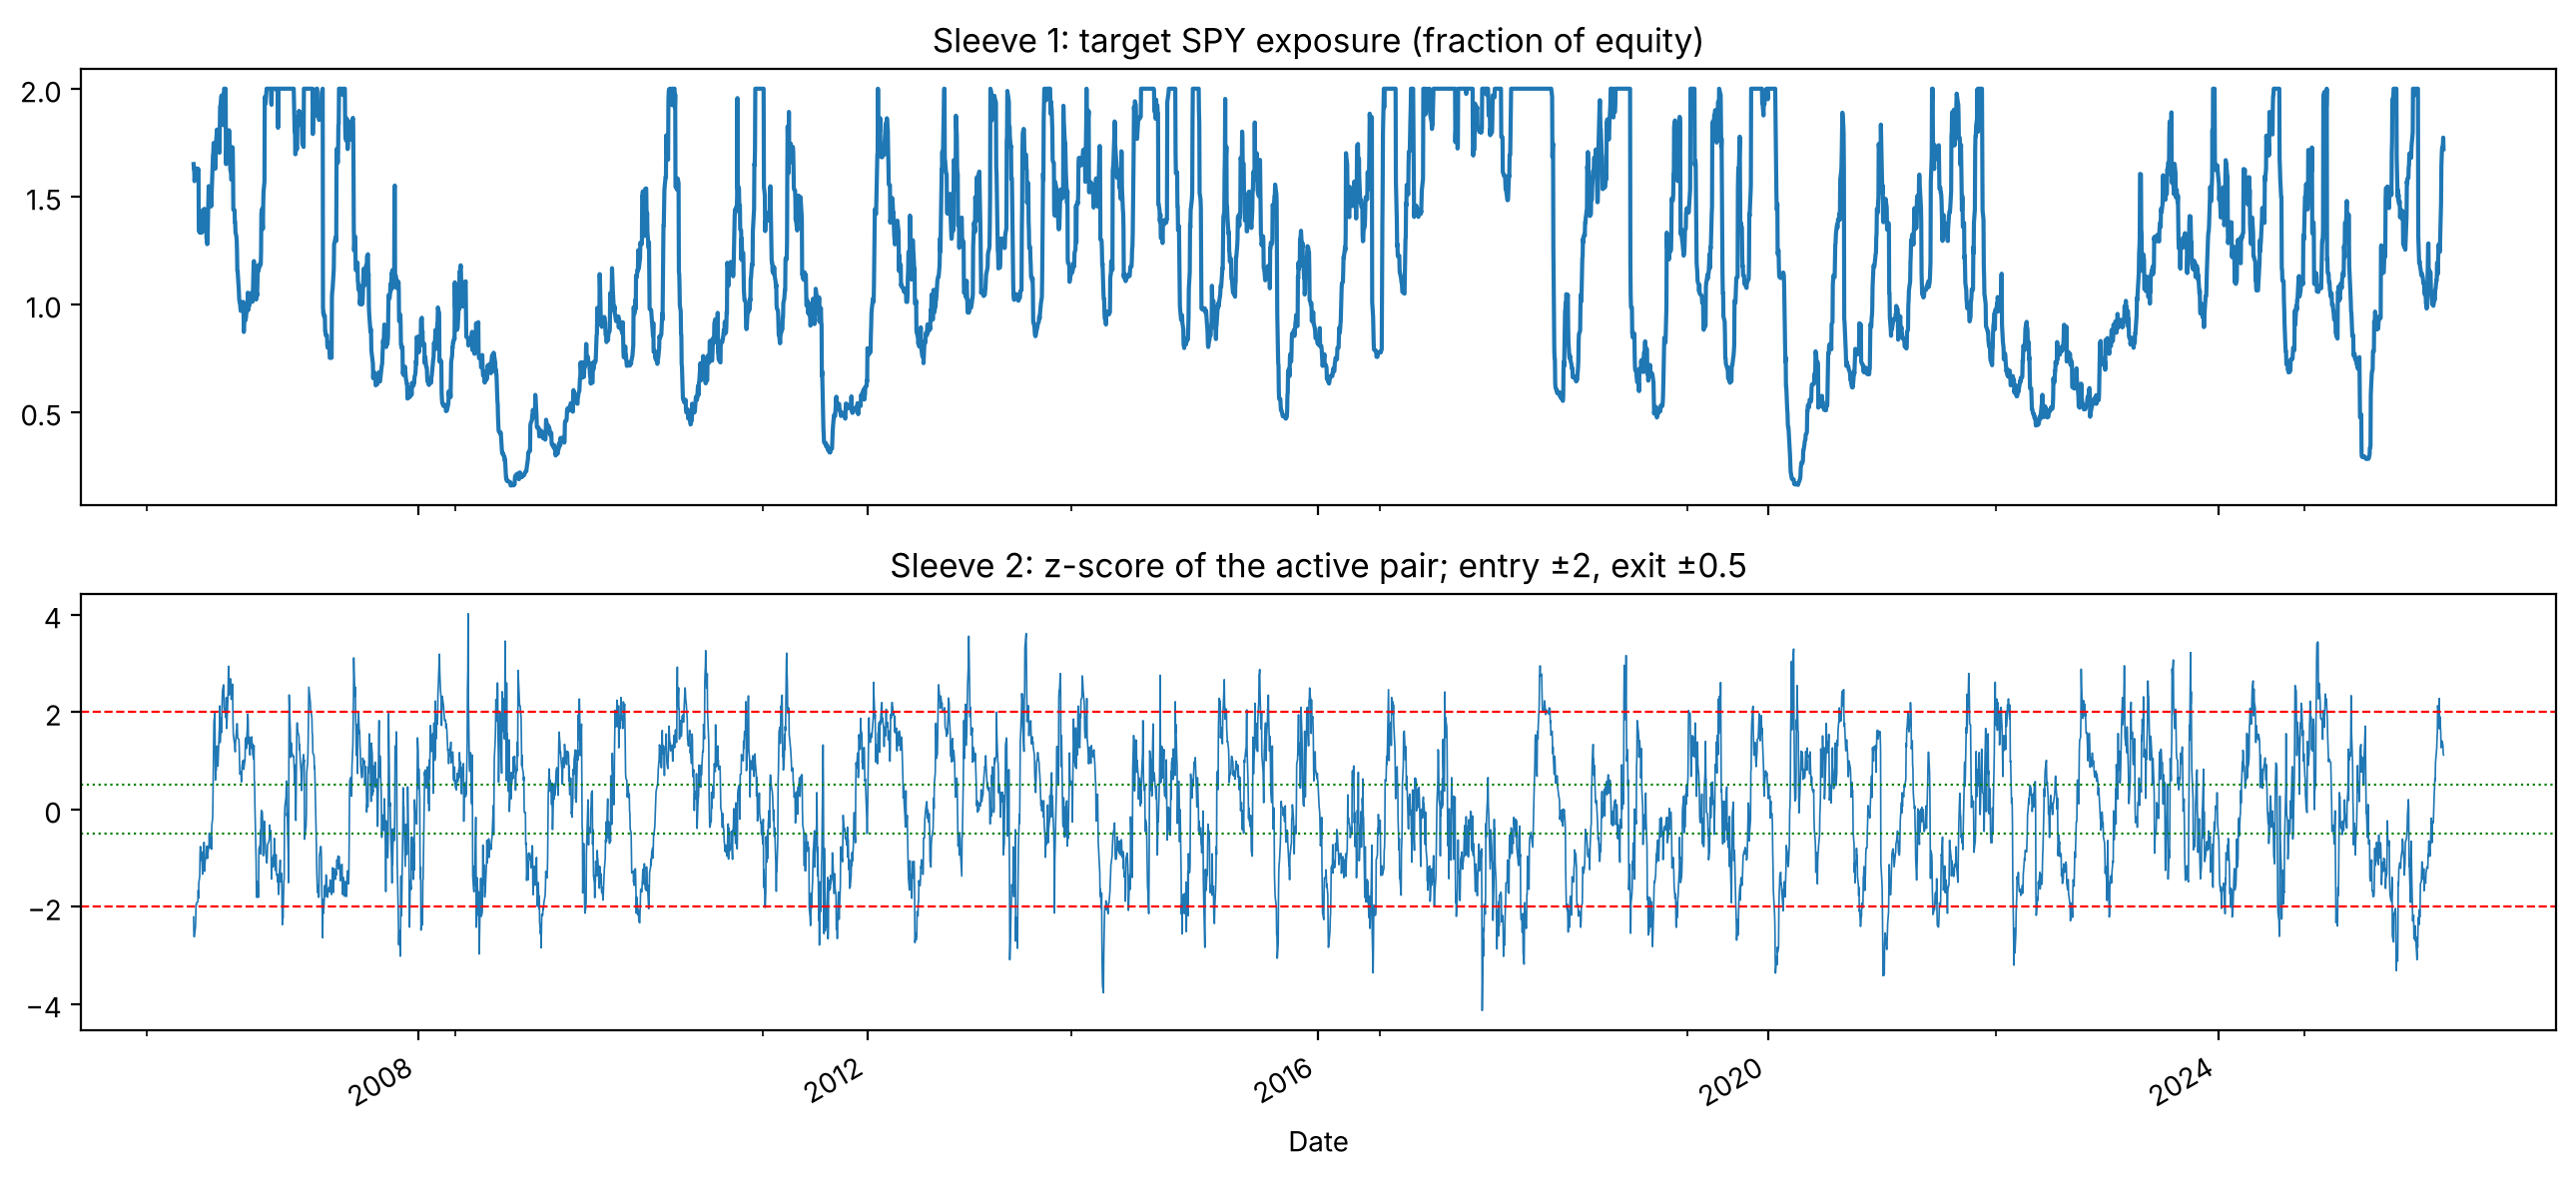

pair position open on 43% of days


In [7]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
expo.loc[START:END].plot(ax=ax[0], title='Sleeve 1: target SPY exposure (fraction of equity)')
z_active.loc[START:END].plot(ax=ax[1], lw=.6, title='Sleeve 2: z-score of the active pair; entry ±2, exit ±0.5')
for h in [Z_IN, -Z_IN]: ax[1].axhline(h, c='r', ls='--', lw=.8)
for h in [Z_OUT, -Z_OUT]: ax[1].axhline(h, c='g', ls=':', lw=.8)
plt.tight_layout(); plt.show()
open_ = tgt_pair.abs().sum(axis=1).loc[START:END] > 0
print(f'pair position open on {open_.mean():.0%} of days')

## 4. Backtest engine
We simulate the account day by day, holding positions between trades:

1. Weights set at the close of day *t−1* earn day *t*'s returns. Uninvested cash earns the T-bill rate; borrowed cash pays T-bill + 0.5%; short notional pays a 0.25% p.a. borrow fee.
2. Positions then **drift** with prices. There is no hidden daily rebalancing.
3. At the close of day *t* the strategy trades only (a) on the last trading day of each month, to reset SPY exposure, and (b) when the pair target changes (a trade opens or closes, or the pair is switched at year-end).
4. Transaction cost = `COST × |target weight − drifted weight|`, summed over assets. Turnover is reported.

`lag=2` delays every trade by one extra day (signal at close *t*, trade at close *t+1*) as a robustness check.

In [8]:
def backtest(px, use_spy=True, pair_size=PAIR_SIZE, cost=COST, lag=1, pair_kw={}):
    e = spy_exposure(px) if use_spy else pd.Series(0.0, index=px.index)
    tp = pair_targets(px, **pair_kw)[0]
    me = pd.Series(month_end_flag(px.index), index=px.index)
    e, tp, me = e.shift(lag - 1), tp.shift(lag - 1).fillna(0), me.shift(lag - 1, fill_value=False)

    i0 = px.index.searchsorted(pd.Timestamp(START)) - 1          # last close before START: initial trade
    idx = px.index[i0:][px.index[i0:] <= pd.Timestamp(END)]
    R = px[ASSETS].pct_change().loc[idx].values
    rf, e, P, me = rf_d.loc[idx].values, e.loc[idx].values, tp.loc[idx].values * pair_size, me.loc[idx].values

    w, prev, rows = np.zeros(len(ASSETS)), np.zeros(len(SECTORS)), []
    for i in range(len(idx)):
        if i == 0:
            gross, w_drift = 0.0, w.copy()                           # nothing held before the first close
        else:
            cash = 1 - w.sum()
            gross = w @ R[i] + cash * (rf[i] + (FIN_SPREAD / 252 if cash < 0 else 0)) \
                    - np.abs(np.minimum(w, 0)).sum() * SHORT_FEE / 252
            w_drift = w * (1 + R[i]) / (1 + gross)
        tgt = w_drift.copy()
        if i == 0 or me[i]:
            tgt[0] = e[i]
        if not np.array_equal(P[i], prev):
            tgt[1:] = P[i]
            prev = P[i]
        turn = np.abs(tgt - w_drift).sum()
        rows.append((gross, gross - turn * cost, turn, tgt[0], np.abs(tgt).sum()))
        w = tgt
    out = pd.DataFrame(rows, index=idx, columns=['gross', 'net', 'turnover', 'w_spy', 'gross_exposure'])
    return out.iloc[1:]                                           # returns start on the first day after START's close

bt = backtest(px)
print(bt.describe().T[['mean', 'min', 'max']])

                    mean       min       max
gross           0.000825 -0.086895  0.103902
net             0.000723 -0.086895  0.103902
turnover        0.102236  0.000000  3.005370
w_spy           1.202789  0.129527  2.165231
gross_exposure  2.062274  0.129527  4.426773


## 5. No look-ahead proof (truncation test)
If any calculation used future data, deleting the future would change the past. We delete every price after a cutoff date and assert that signals, pair choices and strategy returns up to that date are **identical**.

In [9]:
for cut in ['2010-06-30', '2015-12-31', '2020-03-31']:
    px_cut = px.loc[:cut]
    assert np.allclose(spy_exposure(px).loc[:cut].dropna(), spy_exposure(px_cut).dropna())
    assert np.allclose(pair_targets(px)[0].loc[:cut], pair_targets(px_cut)[0])
    full, trunc = backtest(px).loc[:cut], backtest(px_cut)
    assert np.allclose(full.values, trunc.values), cut
    print(f'cut-off {cut}: signals, pair choices and {len(trunc)} daily returns identical with and without future data ✓')

cut-off 2010-06-30: signals, pair choices and 1131 daily returns identical with and without future data ✓


cut-off 2015-12-31: signals, pair choices and 2517 daily returns identical with and without future data ✓


cut-off 2020-03-31: signals, pair choices and 3585 daily returns identical with and without future data ✓


**Why dividend-adjusted prices do not leak information into the pair signal.** `auto_adjust=True` rescales all prices *before* each dividend by a factor. Inside the 60-day z-score window, factors from dividends paid *after* day *t* multiply every price in the window equally. They add a constant to the log price ratio and cancel out of `(s − mean)/std`. Betas and volatilities use returns, which the adjustment leaves correct. The truncation test above confirms this numerically.

## 6. Performance vs. benchmark

In [10]:
monthly = lambda r: (1 + r).resample('ME').prod() - 1
bench_d = ret['^SP500TR'].loc[bt.index]
rf_m = monthly(rf_d.loc[bt.index])
bench_m = monthly(bench_d)

def stats(r_m):
    # Monthly-return statistics. Means x12, volatilities x sqrt(12); beta not annualised.
    rf, b = rf_m.loc[r_m.index], bench_m.loc[r_m.index]
    ex, bex = r_m - rf, b - rf
    ols = sm.OLS(ex, sm.add_constant(bex)).fit()
    a, beta = ols.params.iloc[0], ols.params.iloc[1]
    wealth = (1 + r_m).cumprod()
    return pd.Series({
        'Ann. avg return': r_m.mean() * 12,
        'Ann. volatility': r_m.std() * np.sqrt(12),
        'Sharpe ratio': ex.mean() / ex.std() * np.sqrt(12),
        'Alpha (ann.)': a * 12,
        'Alpha t-stat': ols.tvalues.iloc[0],
        'Beta': beta,
        'Information ratio': a / ols.resid.std() * np.sqrt(12),
        'Max drawdown (monthly)': (wealth / wealth.cummax() - 1).min(),
    })

strat_m = monthly(bt.net)
table = pd.DataFrame({'Strategy (net)': stats(strat_m), 'Strategy (gross)': stats(monthly(bt.gross)),
                      'S&P 500 TR': stats(bench_m)})
table.loc[['Alpha t-stat', 'Information ratio'], 'S&P 500 TR'] = np.nan   # benchmark regressed on itself: undefined
print(f'{len(strat_m)} monthly observations, {strat_m.index[0]:%Y-%m} to {strat_m.index[-1]:%Y-%m}')
table.round(4)

240 monthly observations, 2006-01 to 2025-12


,Strategy (net),Strategy (gross),S&P 500 TR
Ann. avg return,0.1747,0.2008,0.1163
Ann. volatility,0.1566,0.1571,0.1509
Sharpe ratio,1.0121,1.1750,0.6630
Alpha (ann.),0.0741,0.1007,-0.0000
Alpha t-stat,3.5606,4.7392,NaN
Beta,0.8434,0.8380,1.0000
Information ratio,0.8124,1.0813,NaN
Max drawdown (monthly),-0.2678,-0.2346,-0.5095


**Calculation assumptions**
* Statistics use monthly returns compounded from daily returns: 240 months, January 2006 to December 2025.
* Annualised average return = mean monthly return × 12. Volatility = monthly std × √12.
* Sharpe = mean(R − Rf) / std(R − Rf) × √12, with Rf from ^IRX.
* Alpha and beta come from the OLS regression R − Rf = α + β (R_SP500TR − Rf) + ε. Alpha is annualised (×12); **beta is not**.
* Information ratio = α / σ(ε) × √12, i.e. alpha per unit of residual (benchmark-unrelated) risk.
* Net returns include 10 bp per unit traded, T-bill + 0.5% on borrowed cash, and a 0.25% p.a. short-borrow fee. No taxes.

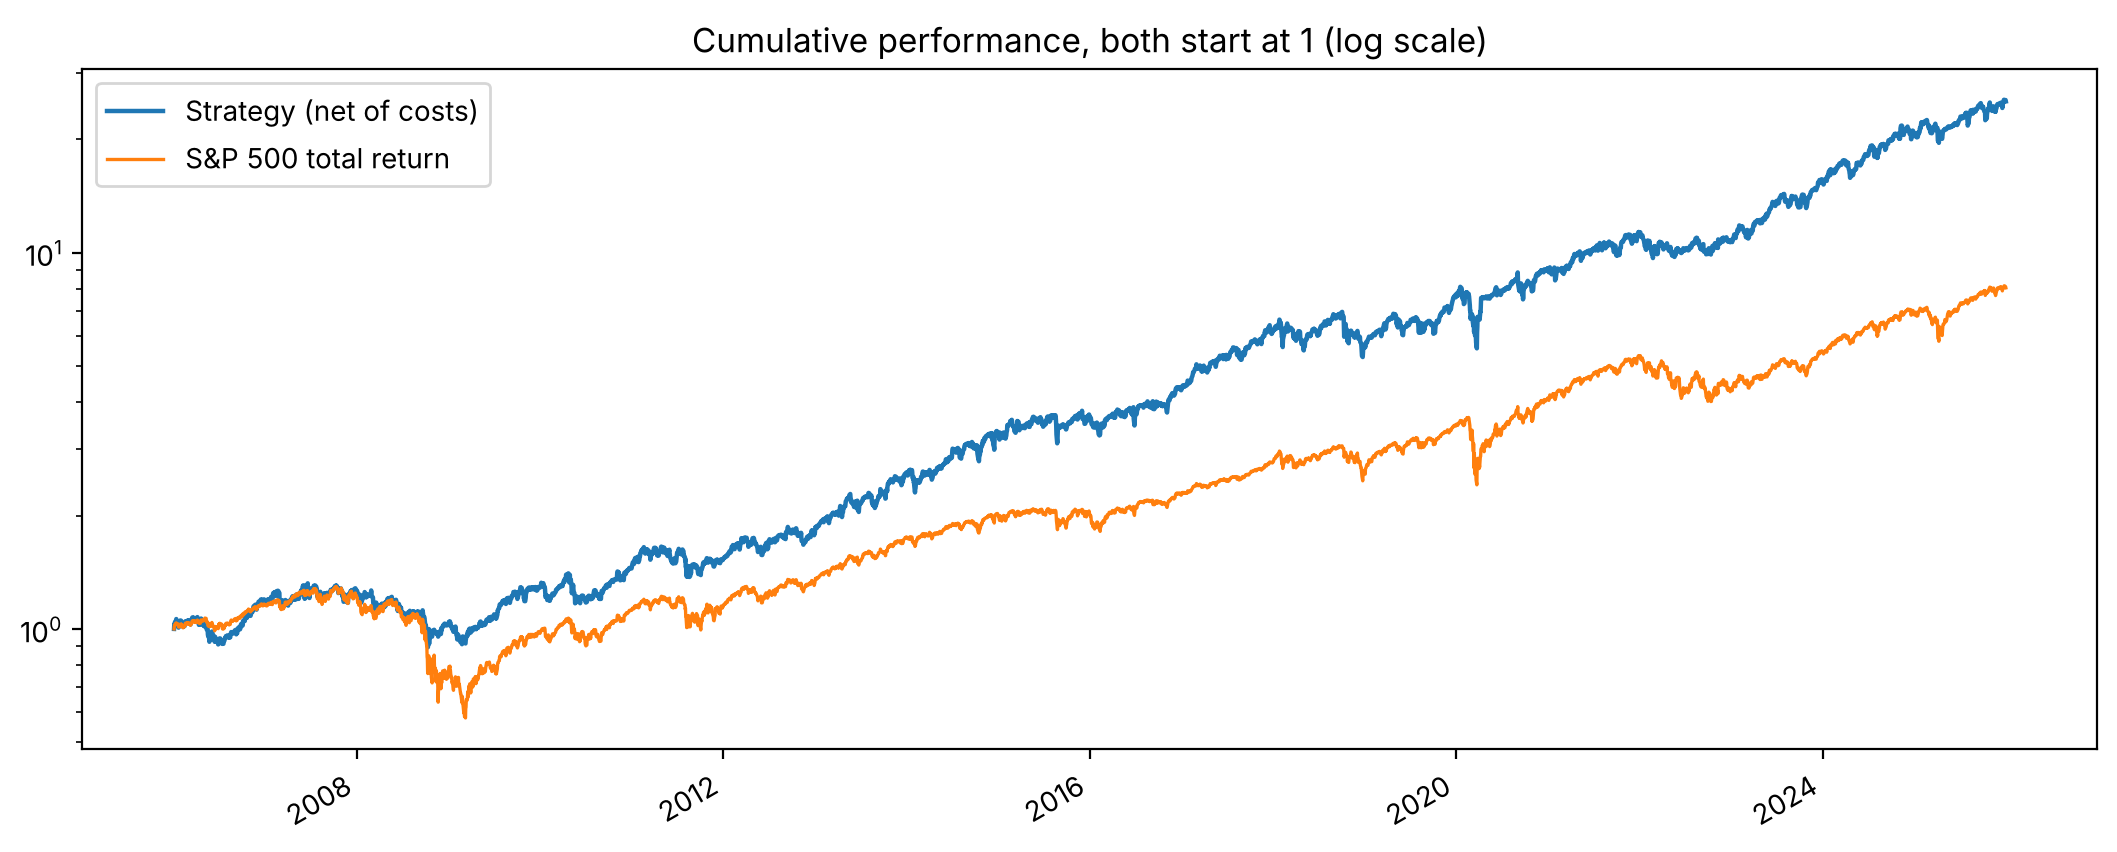

$1 grew to: strategy 25.23, S&P 500 TR 8.06


In [11]:
def wealth(r):
    w = (1 + r).cumprod()
    return pd.concat([pd.Series(1.0, index=[w.index[0] - pd.Timedelta(days=1)]), w])

fig, ax = plt.subplots(figsize=(13, 5))
wealth(bt.net).plot(ax=ax, label='Strategy (net of costs)', lw=1.6)
wealth(bench_d).plot(ax=ax, label='S&P 500 total return', lw=1.2)
ax.set_yscale('log'); ax.set_title('Cumulative performance, both start at 1 (log scale)'); ax.legend(); plt.show()
print(f'$1 grew to: strategy {wealth(bt.net).iloc[-1]:.2f}, S&P 500 TR {wealth(bench_d).iloc[-1]:.2f}')

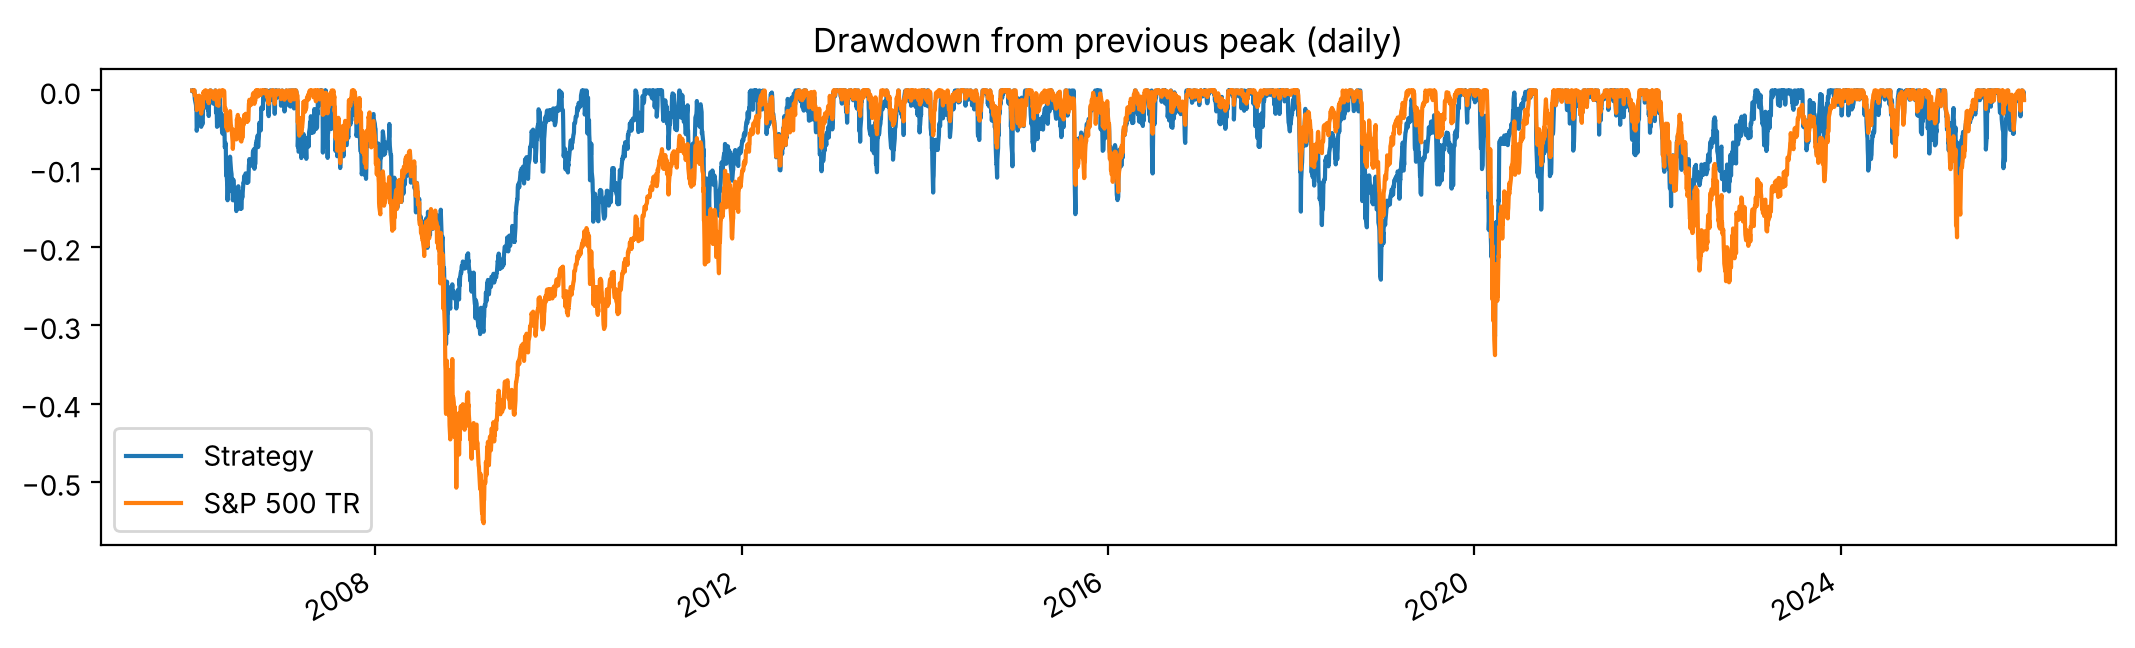

daily max drawdown: strategy -32.4%, benchmark -55.3%


In [12]:
dd = lambda r: wealth(r) / wealth(r).cummax() - 1
fig, ax = plt.subplots(figsize=(13, 3.5))
dd(bt.net).plot(ax=ax, label='Strategy'); dd(bench_d).plot(ax=ax, label='S&P 500 TR')
ax.set_title('Drawdown from previous peak (daily)'); ax.legend(); plt.show()
print('daily max drawdown: strategy {:.1%}, benchmark {:.1%}'.format(dd(bt.net).min(), dd(bench_d).min()))

## 7. Where does the profit come from? (attribution)

In [13]:
spy_only  = backtest(px, use_spy=True,  pair_size=0)      # sleeve 1 alone, pair switched off
pair_only = backtest(px, use_spy=False, pair_size=1.0)    # sleeve 2 alone, capital otherwise in T-bills
sleeves = {'Vol-managed SPY only': spy_only.net, 'Pair only (+ T-bills)': pair_only.net, 'Combined strategy': bt.net}
attr = pd.DataFrame({k: stats(monthly(v)) for k, v in sleeves.items()})
attr.loc['Ann. excess return over T-bills'] = {k: (monthly(v) - rf_m).mean() * 12 for k, v in sleeves.items()}
attr.loc['$1 grows to'] = {k: wealth(v).iloc[-1] for k, v in sleeves.items()}
print('correlation of monthly returns, SPY sleeve vs pair sleeve:',
      round(monthly(spy_only.net).corr(monthly(pair_only.net)), 3))
attr.round(4)

correlation of monthly returns, SPY sleeve vs pair sleeve: -0.09


,Vol-managed SPY only,Pair only (+ T-bills),Combined strategy
Ann. avg return,0.1293,0.0627,0.1747
Ann. volatility,0.1455,0.0725,0.1566
Sharpe ratio,0.7773,0.6436,1.0121
Alpha (ann.),0.0290,0.0464,0.0741
Alpha t-stat,1.7831,2.8147,3.5606
Beta,0.8409,0.0010,0.8434
Information ratio,0.4068,0.6422,0.8124
Max drawdown (monthly),-0.3278,-0.1459,-0.2678
Ann. excess return over T-bills,0.1131,0.0465,0.1585
$1 grows to,10.6107,3.3193,25.2279


Excess return: SPY sleeve 11.31% + pair 4.65% = 15.96% (combined actual 15.85%; the gap is compounding/interaction)
Share of excess return: SPY sleeve 71%, pair 29%
Alpha: SPY sleeve 2.90%, pair 4.64%, combined 7.41%


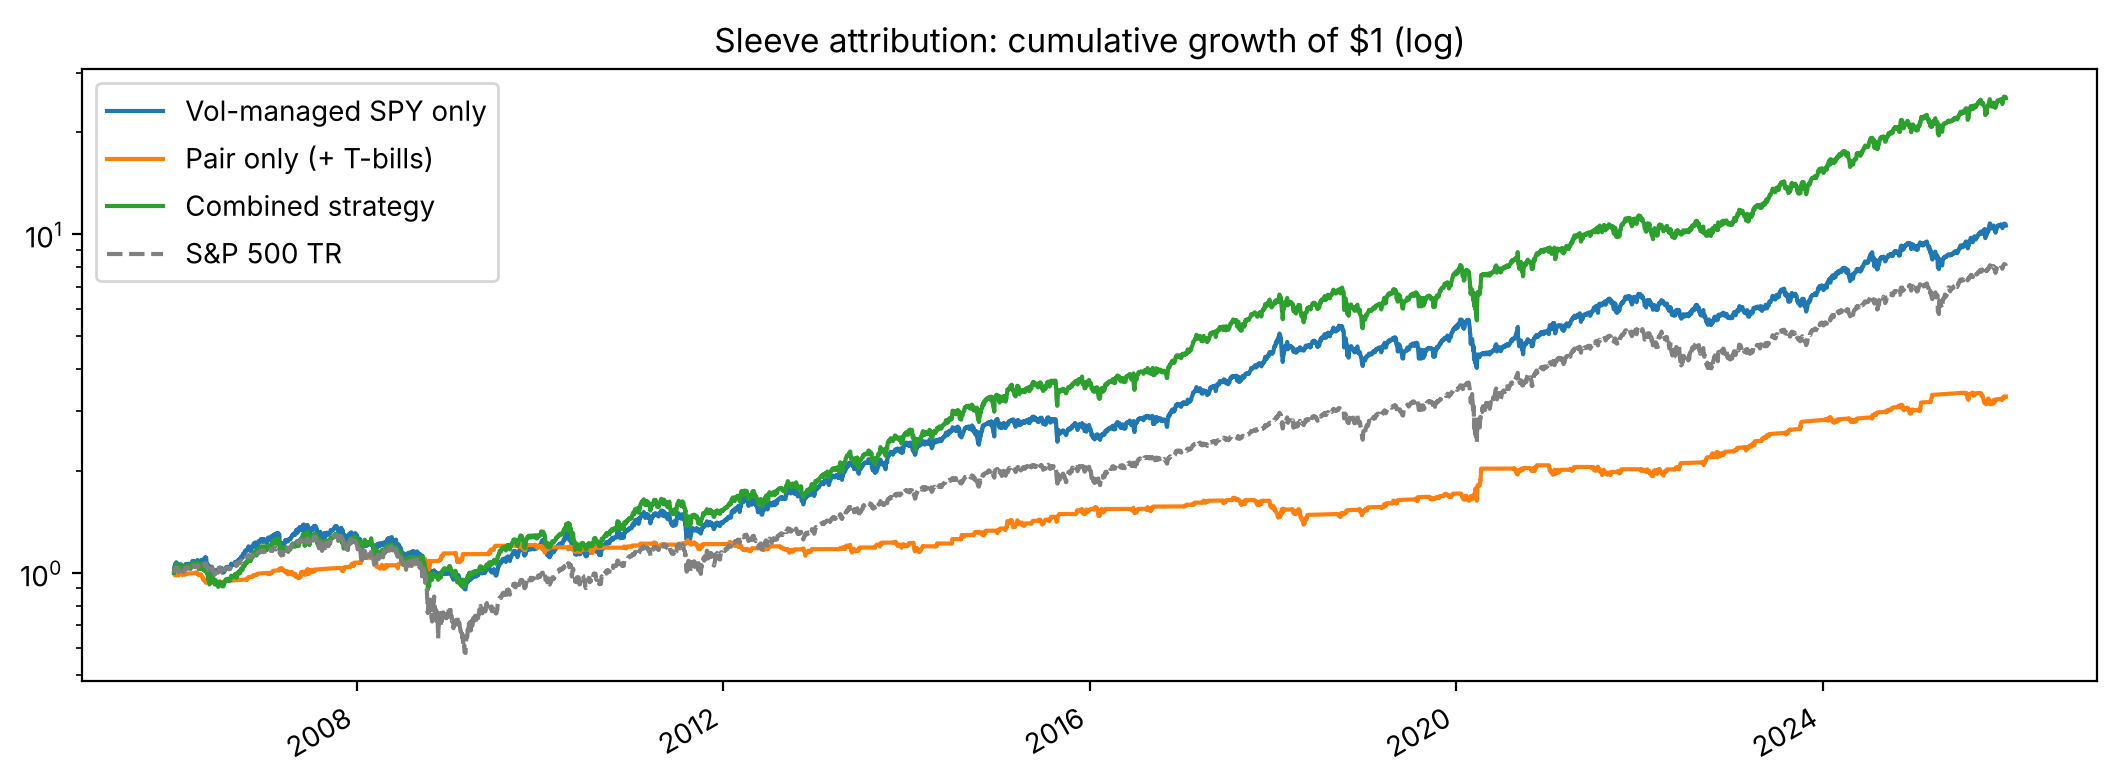

In [14]:
ex = attr.loc['Ann. excess return over T-bills']
share = ex.iloc[:2] / ex.iloc[:2].sum()
print(f"Excess return: SPY sleeve {ex.iloc[0]:.2%} + pair {ex.iloc[1]:.2%} = {ex.iloc[:2].sum():.2%} "
      f"(combined actual {ex.iloc[2]:.2%}; the gap is compounding/interaction)")
print(f"Share of excess return: SPY sleeve {share.iloc[0]:.0%}, pair {share.iloc[1]:.0%}")
al = attr.loc['Alpha (ann.)']
print(f"Alpha: SPY sleeve {al.iloc[0]:.2%}, pair {al.iloc[1]:.2%}, combined {al.iloc[2]:.2%}")
fig, ax = plt.subplots(figsize=(13, 4.5))
for k, v in sleeves.items(): wealth(v).plot(ax=ax, label=k)
wealth(bench_d).plot(ax=ax, label='S&P 500 TR', ls='--', c='grey')
ax.set_yscale('log'); ax.set_title('Sleeve attribution: cumulative growth of $1 (log)'); ax.legend(); plt.show()

## 8. Implementation: turnover, leverage and costs

In [15]:
years = len(bt) / 252
gross_pair = tgt_pair.abs().sum(axis=1)
impl = pd.Series({
    'Turnover per year (x equity)': bt.turnover.sum() / years,
    'Annual cost drag (gross - net)': (bt.gross - bt.net).sum() / years,
    'Avg SPY exposure': bt.w_spy.mean(),
    'Avg gross exposure': bt.gross_exposure.mean(),
    'Max gross exposure': bt.gross_exposure.max(),
    'Pair trades opened': int(((gross_pair > 0) & (gross_pair.shift() == 0)).loc[START:END].sum()),
})
print(impl.round(3).to_string())

be = {c: stats(monthly(backtest(px, cost=c / 1e4).net))['Sharpe ratio'] for c in [0, 5, 10, 20, 30, 50]}
print('\nSharpe ratio by cost per unit traded (bp):', {k: round(float(v), 2) for k, v in be.items()})

Turnover per year (x equity)       25.763
Annual cost drag (gross - net)      0.026
Avg SPY exposure                    1.203
Avg gross exposure                  2.062
Max gross exposure                  4.427
Pair trades opened                107.000



Sharpe ratio by cost per unit traded (bp): {0: 1.18, 5: 1.09, 10: 1.01, 20: 0.85, 30: 0.68, 50: 0.35}


## 9. Robustness

In [16]:
rob = pd.DataFrame({
    'Base case':                 stats(strat_m),
    'Execution lag 2 days':      stats(monthly(backtest(px, lag=2).net)),
    f'In-sample ..{IS_END[:4]}': stats(strat_m.loc[:IS_END]),
    f'Out-of-sample {int(IS_END[:4]) + 1}..': stats(strat_m.loc[IS_END:].iloc[1:]),
}).loc[['Ann. avg return', 'Ann. volatility', 'Sharpe ratio', 'Alpha (ann.)', 'Beta', 'Information ratio']]
rob.round(4)

,Base case,Execution lag 2 days,In-sample ..2015,Out-of-sample 2016..
Ann. avg return,0.1747,0.1672,0.1408,0.2086
Ann. volatility,0.1566,0.1560,0.1477,0.1650
Sharpe ratio,1.0121,0.9682,0.8769,1.1350
Alpha (ann.),0.0741,0.0689,0.0736,0.0716
Beta,0.8434,0.8196,0.7897,0.8961
Information ratio,0.8124,0.7263,0.8362,0.7624


In [17]:
grid = pd.DataFrame({w: {zi: stats(monthly(backtest(px, use_spy=False, pair_kw=dict(win=w, z_in=zi)).net))['Sharpe ratio']
                         for zi in [1.5, 2.0, 2.5]} for w in [40, 60, 90, 120]}).T
grid.index.name, grid.columns.name = 'window (days)', 'entry z'
print('Pair sleeve alone, net Sharpe ratio across signal parameters (base case: 60 days, z = 2.0):')
grid.round(2)

Pair sleeve alone, net Sharpe ratio across signal parameters (base case: 60 days, z = 2.0):


entry z,1.5,2.0,2.5
window (days),,,
40,0.00,0.45,0.18
60,0.37,0.64,0.62
90,0.60,0.68,0.82
120,0.65,0.74,0.79


### Pair-selection rule: alternatives and selection-bias check
Earlier exploration found that a fixed XLU/XLP pair performed well. We then formulated the low-beta rule as an economically motivated, mechanical way to select a pair, so this check matters. The table compares the base rule with longer beta look-backs, a one-off selection on 1999–2005 data, the fixed XLU/XLP pair (hindsight), and **every one of the 36 possible fixed sector pairs**.

In [18]:
def pair_sharpes(**kw):
    p = backtest(px, use_spy=False, pair_kw=kw).net
    c = backtest(px, pair_kw=kw).net
    return pd.Series({'Pair sleeve Sharpe': stats(monthly(p))['Sharpe ratio'],
                      'Combined Sharpe': stats(monthly(c))['Sharpe ratio']})

static_pair = tuple(sorted(sector_betas(px, '1999', '2005').nsmallest(2).index))
rules = {
    'Base: lowest-beta pair, 1y betas':   {},
    'Lowest-beta pair, 3y betas':         dict(pick=lambda px, y: lowbeta_pick(px, y, 3)),
    'Lowest-beta pair, 5y betas':         dict(pick=lambda px, y: lowbeta_pick(px, y, 5)),
    f'Static: 1999-2005 betas ({"/".join(static_pair)})': dict(pick=lambda px, y: static_pair),
    'Fixed XLP/XLU (hindsight)':          dict(pick=lambda px, y: ('XLP', 'XLU')),
}
pd.DataFrame({k: pair_sharpes(**v) for k, v in rules.items()}).T.round(2)

,Pair sleeve Sharpe,Combined Sharpe
"Base: lowest-beta pair, 1y betas",0.64,1.01
"Lowest-beta pair, 3y betas",0.58,0.97
"Lowest-beta pair, 5y betas",0.51,0.93
Static: 1999-2005 betas (XLE/XLP),-0.11,0.40
Fixed XLP/XLU (hindsight),0.69,1.04


In [19]:
from itertools import combinations
all36 = pd.Series({f'{a}/{b}': stats(monthly(backtest(px, use_spy=False, pair_kw=dict(pick=lambda px, y, a=a, b=b: (a, b))).net))['Sharpe ratio']
                   for a, b in combinations(SECTORS, 2)}).sort_values(ascending=False)
print(f'All 36 fixed sector pairs, pair sleeve net Sharpe: mean {all36.mean():.2f}, median {all36.median():.2f}, '
      f'{(all36 > 0).sum()} of 36 positive; XLP/XLU ranks #{all36.index.get_loc("XLP/XLU") + 1}')
all36.round(2).to_frame('Sharpe').T

All 36 fixed sector pairs, pair sleeve net Sharpe: mean -0.01, median -0.04, 17 of 36 positive; XLP/XLU ranks #1


,XLP/XLU,XLU/XLV,XLB/XLI,XLB/XLP,XLK/XLU,XLB/XLY,XLB/XLK,XLF/XLI,XLB/XLV,XLF/XLK,...,XLE/XLK,XLI/XLP,XLU/XLY,XLE/XLF,XLF/XLP,XLP/XLY,XLE/XLU,XLI/XLY,XLE/XLY,XLI/XLV
Sharpe,0.69,0.34,0.31,0.27,0.23,0.17,0.16,0.13,0.11,0.09,...,-0.15,-0.17,-0.17,-0.18,-0.21,-0.22,-0.22,-0.34,-0.38,-0.41


In [20]:
yearly = pd.DataFrame({'Strategy': (1 + bt.net).groupby(bt.index.year).prod() - 1,
                       'SPY sleeve': (1 + spy_only.net).groupby(spy_only.index.year).prod() - 1,
                       'Pair sleeve': (1 + pair_only.net).groupby(pair_only.index.year).prod() - 1,
                       'S&P 500 TR': (1 + bench_d).groupby(bench_d.index.year).prod() - 1})
print('years strategy beat benchmark:', (yearly.Strategy > yearly['S&P 500 TR']).sum(), 'of', len(yearly))
out = (yearly * 100).round(1)
out['pair held'] = betas['pair held'].reindex(out.index)
out

years strategy beat benchmark: 16 of 20


,Strategy,SPY sleeve,Pair sleeve,S&P 500 TR,pair held
Date,,,,,
2006,18.5,24.6,-0.1,15.8,XLP/XLV
2007,6.8,3.8,7.4,5.5,XLP/XLU
2008,-18.6,-22.5,6.5,-37.0,XLP/XLV
2009,24.9,19.1,5.2,26.5,XLP/XLV
2010,12.4,13.5,-0.6,15.1,XLP/XLV
2011,5.4,3.7,1.9,2.1,XLP/XLU
2012,18.1,22.1,-3.4,16.0,XLP/XLU
2013,44.6,41.6,2.3,32.4,XLP/XLU
2014,26.1,13.7,11.4,13.7,XLP/XLU


## 10. Risks and limitations (see prospectus for discussion)
* **Selection bias.** The low-beta selection rule was formulated after exploratory work in which a fixed XLU/XLP pair stood out. §9 shows how far the result depends on that. The rule works with 1-, 3- and 5-year beta windows. A one-off selection on 1999–2005 betas does not work, and neither does the average fixed sector pair. The pair sleeve's historical alpha should therefore be read as optimistic. Signal parameters (60 days, ±2σ, 15% vol target, 21 days) are textbook defaults rather than optimised values, and they are not the best values in the grid.
* **Survivorship.** SPY and the 9 sector SPDRs have traded continuously since 1998. They are diversified funds, so no delisted constituents are missing from the sample.
* **Leverage and shorting.** Gross exposure can exceed 4× (2× SPY plus two 100% pair legs, see §8). Clients need a margin account. Borrowing and borrow fees are modelled at fixed spreads.
* **Concentration.** Equity risk is a single index (US large caps). The pair concentrates in two US defensive sectors.
* **Regime risk.** Volatility timing can lag sudden crashes (exposure is reset monthly). The pair can stop mean-reverting if the two sectors decouple structurally.
* **Data.** ^IRX is a discount-basis yield used as an approximation of the T-bill return. Yahoo data is not point-in-time audited.

## Generative-AI disclosure
_TODO (group to complete and verify):_ Claude Code (Anthropic) was used to screen candidate non-momentum strategies in a separate sandbox (`sandbox/` folder in the repository) and to write and debug this notebook. All outputs were checked by: the truncation test for look-ahead (§5), the SPY vs ^SP500TR sanity check (§2), gross-vs-net and cost-breakeven analysis (§8), the selection-bias checks (§9), and re-running the notebook in a fresh Colab session. Instructor approval for AI-assisted strategy screening: _TODO_.